In [1]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv('datasets/Churn_Modelling.csv')

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df.shape

(10000, 14)

In [5]:
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [8]:
df.drop(columns = ['RowNumber','CustomerId','Surname'],inplace=True)

In [9]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
df['Exited'].value_counts()

,count
Exited,
0,7963
1,2037


In [11]:
df['Geography'].value_counts()

,count
Geography,
France,5014
Germany,2509
Spain,2477


In [12]:
df['Gender'].value_counts()

,count
Gender,
Male,5457
Female,4543


In [13]:
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

In [14]:
X = df.drop(columns=['Exited'])
y = df['Exited']

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [16]:
X_train

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
2694,628,29,3,113146.98,2,0,1,124749.08,1,0,1
5140,626,29,4,105767.28,2,0,0,41104.82,0,0,0
2568,612,47,6,130024.87,1,1,1,45750.21,1,0,0
3671,646,52,6,111739.40,2,0,1,68367.18,1,0,0
7427,714,33,8,122017.19,1,0,0,162515.17,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...
2895,621,47,7,107363.29,1,1,1,66799.28,1,0,1
7813,684,63,3,81245.79,1,1,0,69643.31,1,0,0
905,672,45,9,0.00,1,1,1,92027.69,0,0,0
5192,663,39,8,0.00,2,1,1,101168.90,0,0,0


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [18]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [32]:
model = Sequential()

model.add(Dense(7, activation='relu', input_dim=11)) # Hidden Layer
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 7)              │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 92 (368.00 B)

 Trainable params: 92 (368.00 B)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(loss='binary_crossentropy', optimizer='Adam', metrics=['accuracy'])

In [35]:
model_history = model.fit(X_train, y_train, epochs=30, validation_split=0.2)

Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6345 - loss: 2349.1089 - val_accuracy: 0.7063 - val_loss: 1081.9313
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6288 - loss: 623.8142 - val_accuracy: 0.7244 - val_loss: 139.9815
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6411 - loss: 40.3510 - val_accuracy: 0.2331 - val_loss: 48.3092
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6683 - loss: 30.1229 - val_accuracy: 0.7163 - val_loss: 11.2257
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6730 - loss: 21.1286 - val_accuracy: 0.7106 - val_loss: 9.3001
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6861 - loss: 21.8109 - val_accuracy: 0.6831 - val_loss: 12.1930
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6756 - loss: 20.6954 - val_accuracy: 0.4681 - val_loss: 23.8268
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6705 - loss: 18.411

In [36]:
model.layers[0].get_weights()

[array([[-5.5926043e-01, -2.0693719e-01, -8.5777007e-02, -6.2330842e-02,
         -4.6761253e-01, -4.2779309e-01, -6.6502146e-02],
        [-1.5026483e-01, -4.3486413e-02, -4.7099922e-02,  2.9034197e-01,
          6.0503864e-01,  3.7320387e-01,  8.8650636e-02],
        [ 7.4756086e-02, -4.5422292e-01,  4.4769332e-01, -1.5670896e-02,
          2.6546043e-01,  1.8061659e-01, -2.5791937e-01],
        [-5.2079237e-01, -1.5911710e-03,  3.8848989e-02, -5.3449231e-01,
          4.7422814e-01, -5.1389080e-01, -2.5554068e-04],
        [ 4.9920833e-01, -8.3464563e-01,  1.5805428e-01,  3.8791162e-01,
          8.0544151e-02,  1.2573478e-01, -5.7723556e-02],
        [ 4.7155333e-01, -2.5857520e-01,  1.5981320e-01,  5.1857173e-01,
         -6.1491781e-01, -9.1062717e-02,  3.6879731e-03],
        [-4.5228797e-01, -2.0138359e+00,  1.7773790e+00, -9.2077255e-02,
         -8.6260444e-01, -4.8495302e-01, -1.8437781e+00],
        [-4.5129067e-01,  2.5219783e-01,  3.6777982e-01, -4.8938161e-01,
          

In [37]:
model.layers[1].get_weights()

[array([[ 0.09158081],
        [ 0.04997425],
        [-0.7038667 ],
        [-0.36833948],
        [ 0.05828796],
        [ 0.6488084 ],
        [ 0.7047044 ]], dtype=float32),
 array([-0.21430553], dtype=float32)]

In [38]:
y_log = model.predict(X_test_scaled)

y_pred = np.where(y_log > 0.5, 1, 0)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [39]:
model.evaluate(X_test_scaled, y_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6210 - loss: 0.9219


[0.9218894839286804, 0.6209999918937683]

In [40]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, y_pred)

0.621

In [41]:
import matplotlib.pyplot as plt

In [42]:
model_history.history

{'accuracy': [0.6345312595367432,
  0.6287500262260437,
  0.6410937309265137,
  0.6682812571525574,
  0.6729687452316284,
  0.6860937476158142,
  0.6756250262260437,
  0.6704687476158142,
  0.67578125,
  0.6743749976158142,
  0.6782812476158142,
  0.6725000143051147,
  0.6743749976158142,
  0.6800000071525574,
  0.6731250286102295,
  0.6742187738418579,
  0.6832812428474426,
  0.6746875047683716,
  0.6787499785423279,
  0.6809375286102295,
  0.6848437786102295,
  0.6893749833106995,
  0.6896874904632568,
  0.6796875,
  0.6815624833106995,
  0.6873437762260437,
  0.6792187690734863,
  0.6865624785423279,
  0.6865624785423279,
  0.680468738079071],
 'loss': [2349.10888671875,
  623.814208984375,
  40.351043701171875,
  30.12285614013672,
  21.128633499145508,
  21.810853958129883,
  20.695356369018555,
  18.411903381347656,
  19.483348846435547,
  20.04947853088379,
  20.34882164001465,
  18.30656623840332,
  20.646949768066406,
  16.819978713989258,
  16.856962203979492,
  20.5606155395

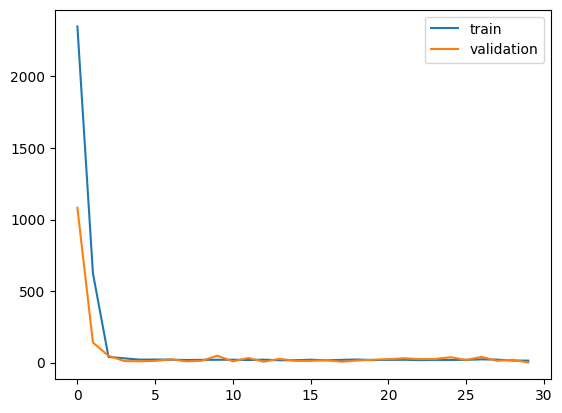

In [43]:
plt.plot(model_history.history['loss'], label='train')
plt.plot(model_history.history['val_loss'], label='validation')
plt.legend()
plt.show()

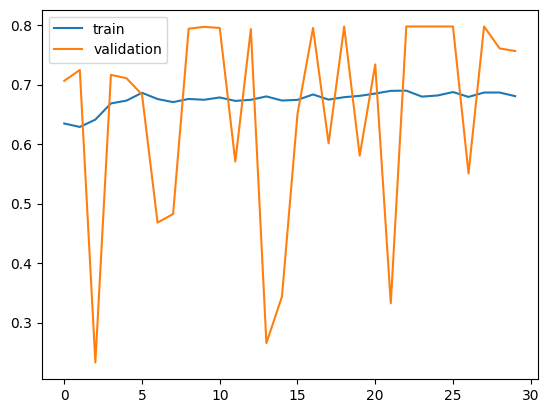

In [44]:
plt.plot(model_history.history['accuracy'], label='train')
plt.plot(model_history.history['val_accuracy'], label='validation')
plt.legend()
plt.show()